In [1]:
import numpy as np

In [2]:
import pandas as pd

In [37]:

import pandas as pd

# Load the new dataset containing original URLs
model_df = pd.read_csv(
    "../data/processed/phishing_features_with_urls.csv"
)

# Define the 21 model features
feature_columns = [
    col for col in model_df.columns
    if col not in ["url", "status"]
]

print("FINAL MODELLING DATASET")
print("-" * 40)

print("Total records:", len(model_df))
print("Total features:", len(feature_columns))

print("\nClass distribution:")
print(
    model_df["status"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Phishing",
        1: "Legitimate"
    })
)

print("\nDataset shape:", model_df.shape)


FINAL MODELLING DATASET
----------------------------------------
Total records: 806758
Total features: 21

Class distribution:
status
Phishing      379785
Legitimate    426973
Name: count, dtype: int64

Dataset shape: (806758, 23)


In [38]:

# Train/Test Split using Registered Domains

import pandas as pd
import tldextract
from urllib.parse import urlsplit
from sklearn.model_selection import StratifiedGroupKFold

# Extract registered domain
def get_registered_domain(url):
    url = str(url).strip()

    if "://" not in url and not url.startswith("//"):
        url = "//" + url

    hostname = urlsplit(url).hostname or ""

    if not hostname:
        return ""

    result = tldextract.extract(hostname)

    return result.top_domain_under_public_suffix or hostname.lower()


# Separate URL and numerical features
url_data = model_df["url"].reset_index(drop=True)

X = model_df[feature_columns].reset_index(drop=True)
y = model_df["status"].reset_index(drop=True)

# Group by registered domain
groups = url_data.apply(get_registered_domain)

# Split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

url_train = url_data.iloc[train_idx]
url_test = url_data.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining features:", X_train.shape[1])

print("\nOverlapping domains:",
      len(set(groups.iloc[train_idx]) &
          set(groups.iloc[test_idx])))


Training records: 645407
Testing records: 161351

Training features: 21

Overlapping domains: 0


In [40]:

# MODEL 1: LOGISTIC REGRESSION

import time

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Train model
print("Starting Logistic Regression training...")

start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

print("Training completed!")

# Predictions
lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

# Evaluation
print("\nLOGISTIC REGRESSION RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, lr_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Phishing", "Legitimate"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, lr_probabilities), 4))

print("\nTraining Time:",
      round(lr_training_time, 2), "seconds")


Starting Logistic Regression training...
Training completed!

LOGISTIC REGRESSION RESULTS
Accuracy: 0.817

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.84      0.76      0.80     75957
  Legitimate       0.80      0.87      0.83     85394

    accuracy                           0.82    161351
   macro avg       0.82      0.81      0.82    161351
weighted avg       0.82      0.82      0.82    161351


Confusion Matrix:
[[57630 18327]
 [11204 74190]]

ROC-AUC: 0.8974

Training Time: 1.09 seconds


In [41]:

# MODEL 2: DECISION TREE

import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create model
dt_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=10,
    random_state=42
)

# Train model
print("Starting Decision Tree training...")

start_time = time.time()

dt_model.fit(X_train, y_train)

dt_training_time = time.time() - start_time

print("Training completed!")

# Predictions
dt_predictions = dt_model.predict(X_test)
dt_probabilities = dt_model.predict_proba(X_test)[:, 1]

# Evaluation
print("\nDECISION TREE RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, dt_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=["Phishing", "Legitimate"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, dt_probabilities), 4))

print("\nTraining Time:",
      round(dt_training_time, 2), "seconds")


Starting Decision Tree training...
Training completed!

DECISION TREE RESULTS
Accuracy: 0.8842

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.90      0.85      0.87     75957
  Legitimate       0.87      0.91      0.89     85394

    accuracy                           0.88    161351
   macro avg       0.89      0.88      0.88    161351
weighted avg       0.88      0.88      0.88    161351


Confusion Matrix:
[[64566 11391]
 [ 7300 78094]]

ROC-AUC: 0.9417

Training Time: 2.46 seconds


In [39]:

# FINAL RANDOM FOREST TRAINING

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=25,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

print("Starting Random Forest training...")

rf_model.fit(X_train, y_train)

print("Training completed!")

# Predictions
rf_predictions = rf_model.predict(X_test)

# Probability of phishing (class 0)
rf_probabilities = rf_model.predict_proba(X_test)[:, 0]

# Evaluation
print("\nFINAL RANDOM FOREST RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Phishing Precision:",
      round(precision_score(y_test, rf_predictions, pos_label=0), 4))

print("Phishing Recall:",
      round(recall_score(y_test, rf_predictions, pos_label=0), 4))

print("Phishing F1:",
      round(f1_score(y_test, rf_predictions, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, rf_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))


Starting Random Forest training...
Training completed!

FINAL RANDOM FOREST RESULTS
Accuracy: 0.9047
Phishing Precision: 0.9324
Phishing Recall: 0.8599
Phishing F1: 0.8947
ROC-AUC: 0.0297

Confusion Matrix:
[[65312 10645]
 [ 4736 80658]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.93      0.86      0.89     75957
  Legitimate       0.88      0.94      0.91     85394

    accuracy                           0.90    161351
   macro avg       0.91      0.90      0.90    161351
weighted avg       0.91      0.90      0.90    161351



In [8]:
#ROC-AUC
# Confusion matrix

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score
)

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

for name, model in models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 0]

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    tp = cm[0, 0]
    fn = cm[0, 1]
    fp = cm[1, 0]
    tn = cm[1, 1]

    specificity = tn / (tn + fp)
    fnr = fn / (fn + tp)
    fpr = fp / (fp + tn)

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        probabilities
    )

    print("\n", name)
    print("ROC-AUC:", round(auc, 4))
    print("Specificity:", round(specificity, 4))
    print("False Negative Rate:", round(fnr, 4))
    print("False Positive Rate:", round(fpr, 4))
    print("Confusion Matrix:\n", cm)


 Logistic Regression
ROC-AUC: 0.9189
Specificity: 0.8797
False Negative Rate: 0.147
False Positive Rate: 0.1203
Confusion Matrix:
 [[52581  9063]
 [ 7736 56570]]

 Decision Tree
ROC-AUC: 0.9692
Specificity: 0.9586
False Negative Rate: 0.0735
False Positive Rate: 0.0414
Confusion Matrix:
 [[57115  4529]
 [ 2661 61645]]

 Random Forest
ROC-AUC: 0.9914
Specificity: 0.9718
False Negative Rate: 0.0592
False Positive Rate: 0.0282
Confusion Matrix:
 [[57995  3649]
 [ 1812 62494]]


In [9]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [10]:
import shap

X_sample = X_test.sample(
    n=200,
    random_state=42
)

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer(X_sample)

print("SHAP Values shape:", shap_values.values.shape)

c:\Users\Pranay Bhardwaj\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP Values shape: (200, 21, 2)


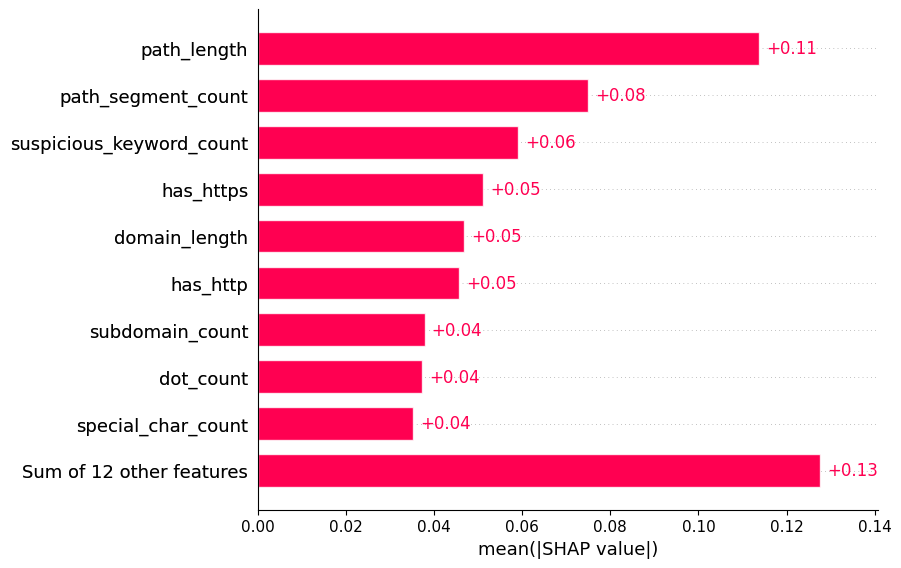

In [11]:
shap.plots.bar(
    shap_values[:, :, 0].abs.mean(0)
)

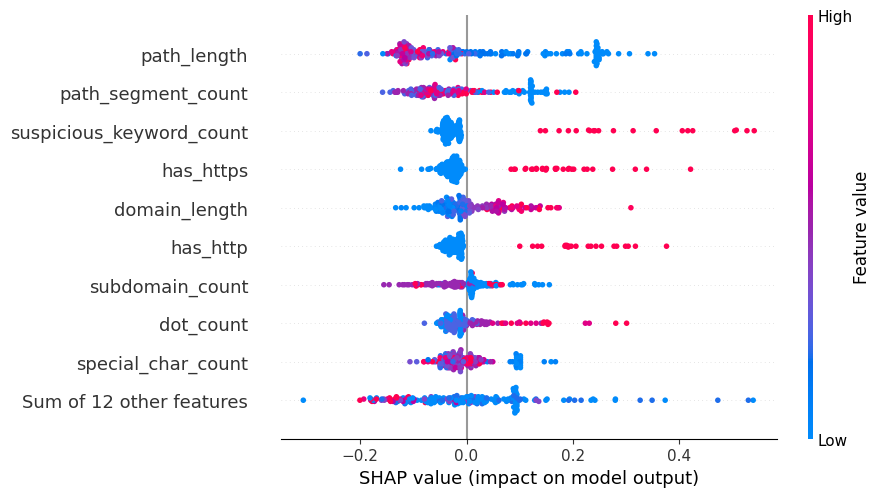

In [12]:
shap.plots.beeswarm(
    shap_values[:, :, 0]
)

In [13]:
print("Model classes:", rf_model.classes_)

print("SHAP output shape:", shap_values.values.shape)

print("\nMean SHAP values for phishing class:")

for i, feature in enumerate(X_sample.columns):
    print(
        feature,
        round(shap_values.values[:, i, 0].mean(), 5)
    )

Model classes: [0 1]
SHAP output shape: (200, 21, 2)

Mean SHAP values for phishing class:
url_length 0.006
dot_count 0.00128
hyphen_count 0.00107
digit_count -0.00164
special_char_count -0.00386
digit_ratio -0.00111
percent_encoding_count 0.00093
has_at_symbol -0.00097
has_https 0.00287
has_http 0.00279
has_fragment -2e-05
path_length 0.00672
path_segment_count -0.01065
query_length 0.00229
query_param_count -0.0004
domain_length 0.00825
subdomain_count -0.00181
has_ip_address -0.00065
has_nonstandard_port -0.00013
suspicious_keyword_count 0.00417
has_shortening_service 0.00033


In [14]:
shap_predictions = (
    shap_values.base_values[:, 0]
    + shap_values.values[:, :, 0].sum(axis=1)
)

actual_predictions = rf_model.predict_proba(X_sample)[:, 0]

print("SHAP reconstructed probabilities:")
print(shap_predictions[:5])

print("\nActual phishing probabilities:")
print(actual_predictions[:5])

print("\nMaximum difference:")
print(np.max(np.abs(shap_predictions - actual_predictions)))

SHAP reconstructed probabilities:
[0.00995293 0.39329975 0.04853343 0.61920741 0.19443914]

Actual phishing probabilities:
[0.00995293 0.39329975 0.04853343 0.61920741 0.19443914]

Maximum difference:
1.3550272015550036e-13


In [15]:
import streamlit

print("Streamlit version:", streamlit.__version__)


Streamlit version: 1.67.0


In [16]:
import sys
import os
import importlib

project_path = os.path.abspath("..")

if project_path not in sys.path:
    sys.path.append(project_path)

import src.feature_extraction

importlib.reload(src.feature_extraction)

from src.feature_extraction import extract_features

In [17]:
google_url = "https://www.google.com"

google_features = extract_features(google_url)

google_df = pd.DataFrame([google_features])

print(google_df.T)

                             0
url_length                22.0
dot_count                  2.0
hyphen_count               0.0
digit_count                0.0
special_char_count         5.0
digit_ratio                0.0
percent_encoding_count     0.0
has_at_symbol              0.0
has_https                  1.0
has_http                   0.0
has_fragment               0.0
path_length                0.0
path_segment_count         0.0
query_length               0.0
query_param_count          0.0
domain_length             14.0
subdomain_count            1.0
has_ip_address             0.0
has_nonstandard_port       0.0
suspicious_keyword_count   0.0
has_shortening_service     0.0


In [18]:
google_prediction = rf_model.predict(google_df)[0]

google_probabilities = rf_model.predict_proba(google_df)[0]

print("Prediction:", google_prediction)

print("Phishing probability:",
      google_probabilities[0] * 100)

print("Legitimate probability:",
      google_probabilities[1] * 100)

Prediction: 0
Phishing probability: 99.60805860805863
Legitimate probability: 0.39194139194139194


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Check feature schema
print("Same feature columns:",
      list(google_df.columns) == list(X_train.columns))

# Find training examples with similar features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
google_scaled = scaler.transform(google_df)

neighbors = NearestNeighbors(n_neighbors=5)

neighbors.fit(X_train_scaled)

distances, indices = neighbors.kneighbors(google_scaled)

# Display nearest training examples
print("\nFive most similar training examples:")

print(
    similar_rows[["status"] + list(X_train.columns)]
    .to_string()
)

print("\nDistances:")
print(distances[0])

Same feature columns: True

Five most similar training examples:


NameError: name 'similar_rows' is not defined

In [ ]:
print("HTTPS distribution by class:")
print(model_df.groupby("status")["has_https"].mean())

print("\nHTTP distribution by class:")
print(model_df.groupby("status")["has_http"].mean())

print("\nAverage URL length by class:")
print(model_df.groupby("status")["url_length"].mean())

HTTPS distribution by class:
status
0    0.24287
1    0.03423
Name: has_https, dtype: float64

HTTP distribution by class:
status
0    0.150607
1    0.052856
Name: has_http, dtype: float64

Average URL length by class:
status
0    51.511685
1    53.314905
Name: url_length, dtype: float64


In [ ]:
google_shap = explainer(google_df)

google_contributions = pd.DataFrame({
    "Feature": X_train.columns,
    "Value": google_df.iloc[0].values,
    "SHAP": google_shap.values[0, :, 0]
})

google_contributions["Absolute_SHAP"] = (
    google_contributions["SHAP"].abs()
)

google_contributions = google_contributions.sort_values(
    "Absolute_SHAP",
    ascending=False
)

print(google_contributions.to_string(index=False))

                 Feature  Value      SHAP  Absolute_SHAP
             path_length    0.0  0.263066       0.263066
      path_segment_count    0.0  0.138925       0.138925
               has_https    1.0  0.132166       0.132166
              url_length   22.0  0.056433       0.056433
         subdomain_count    1.0 -0.024986       0.024986
           domain_length   14.0 -0.021379       0.021379
      special_char_count    5.0 -0.016076       0.016076
suspicious_keyword_count    0.0 -0.012199       0.012199
            query_length    0.0  0.010624       0.010624
             digit_ratio    0.0 -0.009371       0.009371
             digit_count    0.0 -0.008265       0.008265
               dot_count    2.0 -0.008096       0.008096
            hyphen_count    0.0  0.007111       0.007111
                has_http    0.0 -0.005388       0.005388
       query_param_count    0.0  0.005250       0.005250
          has_ip_address    0.0 -0.001315       0.001315
  percent_encoding_count    0.0

In [ ]:
print("Average path length by class:")
print(model_df.groupby("status")["path_length"].mean())

print("\nZero path length percentage:")
print(
    model_df.assign(
        zero_path=model_df["path_length"].eq(0)
    ).groupby("status")["zero_path"].mean() * 100
)

print("\nAverage path segments by class:")
print(model_df.groupby("status")["path_segment_count"].mean())

print("\nZero path segments percentage:")
print(
    model_df.assign(
        zero_segments=model_df["path_segment_count"].eq(0)
    ).groupby("status")["zero_segments"].mean() * 100
)

Average path length by class:
status
0    14.632661
1    33.091428
Name: path_length, dtype: float64

Zero path length percentage:
status
0    40.080916
1     0.033900
Name: zero_path, dtype: float64

Average path segments by class:
status
0    1.320603
1    2.384400
Name: path_segment_count, dtype: float64

Zero path segments percentage:
status
0    51.931257
1     1.906498
Name: zero_segments, dtype: float64


In [ ]:
print("Available DataFrame columns:")
print(model_df.columns.tolist())

Available DataFrame columns:
['url_length', 'dot_count', 'hyphen_count', 'digit_count', 'special_char_count', 'digit_ratio', 'percent_encoding_count', 'has_at_symbol', 'has_https', 'has_http', 'has_fragment', 'path_length', 'path_segment_count', 'query_length', 'query_param_count', 'domain_length', 'subdomain_count', 'has_ip_address', 'has_nonstandard_port', 'suspicious_keyword_count', 'has_shortening_service', 'status']


In [ ]:
raw_df = pd.read_csv("../data/raw/new_data_urls.csv")

print("Original dataset shape:", raw_df.shape)
print(raw_df.head())

Original dataset shape: (822010, 2)
                                       url  status
0  0000111servicehelpdesk.godaddysites.com       0
1     000011accesswebform.godaddysites.com       0
2                             00003.online       0
3      0009servicedeskowa.godaddysites.com       0
4                     000n38p.wcomhost.com       0


In [ ]:
# Phishing URLs with no path
print("PHISHING EXAMPLES:")

print(
    raw_df[
        (raw_df["status"] == 0) &
        (~raw_df["url"].str.contains("/", regex=False))
    ]["url"].head(10).to_string(index=False)
)

# Legitimate URLs with no path
print("\nLEGITIMATE EXAMPLES:")

print(
    raw_df[
        (raw_df["status"] == 1) &
        (~raw_df["url"].str.contains("/", regex=False))
    ]["url"].head(10).to_string(index=False)
)

PHISHING EXAMPLES:
0000111servicehelpdesk.godaddysites.com
   000011accesswebform.godaddysites.com
                           00003.online
    0009servicedeskowa.godaddysites.com
                   000n38p.wcomhost.com
                   000n38t.wcomhost.com
                   000n8pc.wcomhost.com
                   000ne9r.wcomhost.com
                   000njep.wcomhost.com
                   000nku9.wcomhost.com

LEGITIMATE EXAMPLES:
                                             ¾5092
                                @ÒÊ\t¹Ë¨öí
      >Iq9E) l¬0ZÝìÃw!'Ôp£ãW§&£Ñp&$ImÞôöÝYÖ
                       ê­~l+×û¢ïÄÁR"+íI
RybjUxÙãl5»7ÆE%ÝÔk+h|U+ýk©ìÉ½Æq]âF·õÁ...
           §¬I0f9ÎPðÏ}åç`.7õú X'}Ø4~æÊ¸a(_à
¶Ã·¼Øé¯·¤êZ}²^v³ÑÏ¯nD-³ª\áå½^oz¤8\t°...
_WªçM`"ÉÑ¦M9 mPÚôOÀ¿ã±µäLáÉÝrÑ{ÖÊö...
                                                 
     Ä«nLG"Wà@Ùi¿ø·®Ø«·7"ÁÇ¤ç³U!)Ý-Í¦}¥


In [ ]:
# Check non-printable characters in each class

raw_df["is_printable"] = raw_df["url"].astype(str).apply(
    lambda x: x.isprintable()
)

print("Non-printable URL records by class:")

print(
    raw_df.groupby("status")["is_printable"]
    .apply(lambda x: (~x).sum())
)

print("\nTotal records by class:")
print(raw_df["status"].value_counts())

Non-printable URL records by class:
status
0    32
1    98
Name: is_printable, dtype: int64

Total records by class:
status
1    427028
0    394982
Name: count, dtype: int64


In [ ]:
print("Examples of phishing URLs:")
print(
    raw_df[raw_df["status"] == 0]["url"]
    .sample(10, random_state=42)
    .to_string(index=False)
)

print("\nExamples of legitimate URLs:")
print(
    raw_df[raw_df["status"] == 1]["url"]
    .sample(10, random_state=42)
    .to_string(index=False)
)

Examples of phishing URLs:
                              carpetcleaning-a.com
https://www.amznco.jpaplsiginlopedldlpapelvisio...
http://www.yukseldisucuklari.com/sites/all/them...
douglasornellas.com.br/administrator/DHL/index....
             https://www.eki.lxfet.shop/a3IwMDY1P3
                                      aasddsxc.com
starfleetepsilon.com/application/views/secure/D...
                                 paypalsecurity.fr
  https://www2.amazon.co.jp.wwwdfsfsdfgsd.monster/
  https://www.aesocon-asoemsnacosmn.cpqvyri.md.ci/

Examples of legitimate URLs:
                                barrybartlett.net/
 archive.org/stream/cihm_03838/cihm_03838_djvu.txt
                                strategyfirst.net/
                   www.macminute.com/headlines.xml
                        vrealities.com/sensio.html
               news.cnet.com/2100-1040-248127.html
       web.comporium.net/~rmorency/alpha_names.htm
             residentadvisor.net/event.aspx?229879
                       to

In [42]:

# MODEL 4: SUPPORT VECTOR MACHINE (SVM)

import time

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        random_state=42,
        max_iter=5000,
        dual="auto"
    ))
])

# Train model
print("Starting SVM training...")

start_time = time.time()

svm_model.fit(X_train, y_train)

svm_training_time = time.time() - start_time

print("Training completed!")

# Predictions
svm_predictions = svm_model.predict(X_test)

# Decision scores for ROC-AUC
svm_scores = svm_model.decision_function(X_test)

# Evaluation
print("\nSVM RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, svm_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=["Phishing", "Legitimate"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, svm_scores), 4))

print("\nTraining Time:",
      round(svm_training_time, 2), "seconds")


Starting SVM training...
Training completed!

SVM RESULTS
Accuracy: 0.8053

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.85      0.71      0.78     75957
  Legitimate       0.78      0.89      0.83     85394

    accuracy                           0.81    161351
   macro avg       0.81      0.80      0.80    161351
weighted avg       0.81      0.81      0.80    161351


Confusion Matrix:
[[54190 21767]
 [ 9648 75746]]

ROC-AUC: 0.8946

Training Time: 1.93 seconds


In [ ]:
print(
    "Corrected SVM ROC-AUC:",
    roc_auc_score(y_test, svm_scores)
)

Corrected SVM ROC-AUC: 0.9156471395748125


In [43]:

# MODEL 5: XGBOOST

import time

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
print("Starting XGBoost training...")

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

print("Training completed!")

# Predictions
xgb_predictions = xgb_model.predict(X_test)

xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation
print("\nXGBOOST RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, xgb_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["Phishing", "Legitimate"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, xgb_probabilities), 4))

print("\nTraining Time:",
      round(xgb_training_time, 2), "seconds")


Starting XGBoost training...
Training completed!

XGBOOST RESULTS
Accuracy: 0.9035

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.94      0.85      0.89     75957
  Legitimate       0.88      0.95      0.91     85394

    accuracy                           0.90    161351
   macro avg       0.91      0.90      0.90    161351
weighted avg       0.91      0.90      0.90    161351


Confusion Matrix:
[[64771 11186]
 [ 4389 81005]]

ROC-AUC: 0.9713

Training Time: 3.0 seconds


In [44]:

# MLP - Multi-Layer Perceptron

import time

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Create MLP pipeline
mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=256,
        learning_rate_init=0.001,
        max_iter=50,
        early_stopping=True,
        random_state=42
    ))
])

# Train model
print("Starting MLP training...")

start_time = time.time()

mlp_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Training completed!")

# Predictions
mlp_predictions = mlp_model.predict(X_test)

# Probability of legitimate class (1)
mlp_probabilities = mlp_model.predict_proba(X_test)[:, 1]

# Evaluation
print("\nMLP RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, mlp_predictions), 4))

print("Phishing Precision:",
      round(precision_score(y_test, mlp_predictions, pos_label=0), 4))

print("Phishing Recall:",
      round(recall_score(y_test, mlp_predictions, pos_label=0), 4))

print("Phishing F1:",
      round(f1_score(y_test, mlp_predictions, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, mlp_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, mlp_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    mlp_predictions,
    target_names=["Phishing", "Legitimate"]
))

print("Training Time:",
      round(training_time, 2), "seconds")


Starting MLP training...
Training completed!

MLP RESULTS
Accuracy: 0.9034
Phishing Precision: 0.9284
Phishing Recall: 0.8612
Phishing F1: 0.8936
ROC-AUC: 0.9714

Confusion Matrix:
[[65417 10540]
 [ 5046 80348]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.93      0.86      0.89     75957
  Legitimate       0.88      0.94      0.91     85394

    accuracy                           0.90    161351
   macro avg       0.91      0.90      0.90    161351
weighted avg       0.90      0.90      0.90    161351

Training Time: 47.07 seconds


In [46]:

# FINAL MODEL COMPARISON

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Random Forest": (rf_model, rf_predictions),
    "Logistic Regression": (lr_model, lr_predictions),
    "Decision Tree": (dt_model, dt_predictions),
    "SVM": (svm_model, svm_predictions),
    "XGBoost": (xgb_model, xgb_predictions),
    "MLP": (mlp_model, mlp_predictions)
}

comparison_results = []

for name, (model, predictions) in models.items():

    if name == "SVM":
        scores = model.decision_function(X_test)

        # LinearSVC decision scores increase towards class 1
        auc = roc_auc_score(y_test, scores)

    else:
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Phishing Precision": precision_score(
            y_test, predictions, pos_label=0
        ),
        "Phishing Recall": recall_score(
            y_test, predictions, pos_label=0
        ),
        "Phishing F1": f1_score(
            y_test, predictions, pos_label=0
        ),
        "ROC-AUC": auc
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("FINAL MODEL COMPARISON")
print("=" * 80)

print(comparison_df.to_string(
    index=False,
    formatters={
        col: "{:.4f}".format
        for col in comparison_df.select_dtypes(
            include="number"
        ).columns
    }
))


FINAL MODEL COMPARISON
              Model Accuracy Phishing Precision Phishing Recall Phishing F1 ROC-AUC
                MLP   0.9034             0.9284          0.8612      0.8936  0.9714
            XGBoost   0.9035             0.9365          0.8527      0.8927  0.9713
      Random Forest   0.9047             0.9324          0.8599      0.8947  0.9703
      Decision Tree   0.8842             0.8984          0.8500      0.8736  0.9417
Logistic Regression   0.8170             0.8372          0.7587      0.7960  0.8974
                SVM   0.8053             0.8489          0.7134      0.7753  0.8946


In [47]:

import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Random Forest
joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

# Save XGBoost
joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

# Save feature column names and order
joblib.dump(
    list(X_train.columns),
    "../models/feature_columns.pkl"
)

print("MODELS SAVED SUCCESSFULLY!")
print("Random Forest model saved.")
print("XGBoost model saved.")
print("Feature columns saved.")


MODELS SAVED SUCCESSFULLY!
Random Forest model saved.
XGBoost model saved.
Feature columns saved.


In [48]:

import os
import joblib

model_files = [
    "../models/random_forest_model.pkl",
    "../models/xgboost_model.pkl",
    "../models/feature_columns.pkl"
]

print("MODEL FILE VERIFICATION")
print("=" * 40)

for file_path in model_files:
    exists = os.path.exists(file_path)

    print(
        os.path.basename(file_path),
        ":",
        "Available" if exists else "Missing"
    )

# Load saved models
loaded_rf = joblib.load(
    "../models/random_forest_model.pkl"
)

loaded_xgb = joblib.load(
    "../models/xgboost_model.pkl"
)

loaded_features = joblib.load(
    "../models/feature_columns.pkl"
)

print("\nMODEL LOADING VERIFICATION")
print("Random Forest:", type(loaded_rf).__name__)
print("XGBoost:", type(loaded_xgb).__name__)
print("Number of features:", len(loaded_features))


MODEL FILE VERIFICATION
random_forest_model.pkl : Available
xgboost_model.pkl : Available
feature_columns.pkl : Available

MODEL LOADING VERIFICATION
Random Forest: RandomForestClassifier
XGBoost: XGBClassifier
Number of features: 21


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.wikipedia.org",
    "https://www.amazon.com",
    "https://www.github.com",
    "https://www.youtube.com",
    "https://www.python.org",
    "https://www.openai.com",
    "https://www.apple.com",
    "https://www.linkedin.com"
]

for url in test_urls:

    features = extract_features(url)

    test_df = pd.DataFrame([features])

    prediction = rf_model.predict(test_df)[0]

    probabilities = rf_model.predict_proba(test_df)[0]

    phishing_probability = probabilities[
        list(rf_model.classes_).index(0)
    ]

    print(
        url,
        "|",
        "Phishing" if prediction == 0 else "Legitimate",
        "|",
        f"{phishing_probability * 100:.2f}% phishing"
    )

https://www.google.com | Phishing | 99.61% phishing
https://www.microsoft.com | Phishing | 100.00% phishing
https://www.wikipedia.org | Phishing | 100.00% phishing
https://www.amazon.com | Phishing | 99.61% phishing
https://www.github.com | Phishing | 99.61% phishing
https://www.youtube.com | Phishing | 99.67% phishing
https://www.python.org | Phishing | 99.61% phishing
https://www.openai.com | Phishing | 99.61% phishing
https://www.apple.com | Phishing | 98.74% phishing
https://www.linkedin.com | Phishing | 100.00% phishing


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.wikipedia.org",
    "https://www.amazon.com",
    "https://www.github.com"
]

test_features = pd.DataFrame([
    extract_features(url)
    for url in test_urls
])

test_features.index = test_urls

print(test_features.T.to_string())

                          https://www.google.com  https://www.microsoft.com  https://www.wikipedia.org  https://www.amazon.com  https://www.github.com
url_length                                  22.0                       25.0                       25.0                    22.0                    22.0
dot_count                                    2.0                        2.0                        2.0                     2.0                     2.0
hyphen_count                                 0.0                        0.0                        0.0                     0.0                     0.0
digit_count                                  0.0                        0.0                        0.0                     0.0                     0.0
special_char_count                           5.0                        5.0                        5.0                     5.0                     5.0
digit_ratio                                  0.0                        0.0                   

In [20]:

from src.feature_extraction import extract_features
import pandas as pd

test_urls = [
    "google.com",
    "https://google.com",
    "http://google.com",
    "microsoft.com",
    "https://microsoft.com",
    "wikipedia.org",
    "https://wikipedia.org",
    "amazon.com",
    "https://amazon.com",
    "github.com",
    "https://github.com"
]

results = []

for url in test_urls:
    features = extract_features(url)
    results.append({
        "url": url,
        **features
    })

diagnostic_df = pd.DataFrame(results)

print(diagnostic_df.to_string(index=False))


                  url  url_length  dot_count  hyphen_count  digit_count  special_char_count  digit_ratio  percent_encoding_count  has_at_symbol  has_https  has_http  has_fragment  path_length  path_segment_count  query_length  query_param_count  domain_length  subdomain_count  has_ip_address  has_nonstandard_port  suspicious_keyword_count  has_shortening_service
           google.com          10          1             0            0                   1          0.0                       0              0          0         0             0            0                   0             0                  0             10                0               0                     0                         0                       0
   https://google.com          18          1             0            0                   4          0.0                       0              0          1         0             0            0                   0             0                  0             10           

In [22]:
# Display currently defined DataFrame variables

import pandas as pd

dataframe_variables = {
    name: value.shape
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
}

print(dataframe_variables)

{'processed_df': (806758, 22), 'model_df': (629751, 22), 'X': (629751, 21), 'X_train': (503801, 21), 'X_test': (125950, 21), 'X_sample': (200, 21), 'google_df': (1, 21), 'diagnostic_df': (11, 22)}


In [23]:
# Examine homepage-like records in the final modelling dataset

homepage_mask = (
    (model_df["path_length"] == 0) &
    (model_df["path_segment_count"] == 0) &
    (model_df["query_length"] == 0)
)

homepage_df = model_df.loc[homepage_mask]

print("Total homepage-like records:", len(homepage_df))

print("\nClass distribution:")

print(
    homepage_df["status"]
    .value_counts()
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

print("\nPercentage of each class represented by homepage-like records:")

for label, class_name in [(0, "Phishing"), (1, "Legitimate")]:
    class_count = (model_df["status"] == label).sum()
    homepage_count = (homepage_df["status"] == label).sum()

    percentage = homepage_count / class_count * 100

    print(
        f"{class_name}: "
        f"{homepage_count:,} / {class_count:,} "
        f"({percentage:.4f}%)"
    )

Total homepage-like records: 123573

Class distribution:
status
Phishing      123467
Legitimate       106
Name: count, dtype: int64

Percentage of each class represented by homepage-like records:
Phishing: 123,467 / 308,219 (40.0582%)
Legitimate: 106 / 321,532 (0.0330%)


In [24]:
print("MODEL_DF CLASS DISTRIBUTION")
print(model_df["status"].value_counts().sort_index())

print("\nPROCESSED_DF CLASS DISTRIBUTION")
print(processed_df["status"].value_counts().sort_index())

print("\nTARGET LABEL MAPPING")
print("0 = Phishing")
print("1 = Legitimate")

MODEL_DF CLASS DISTRIBUTION
status
0    308219
1    321532
Name: count, dtype: int64

PROCESSED_DF CLASS DISTRIBUTION
status
0    379785
1    426973
Name: count, dtype: int64

TARGET LABEL MAPPING
0 = Phishing
1 = Legitimate


In [25]:
# Inspect legitimate homepage-like records

legitimate_homepages = homepage_df[
    homepage_df["status"] == 1
]

print("Legitimate homepage-like records:")
print(len(legitimate_homepages))

print("\nFirst 30 records:")
print(legitimate_homepages.to_string(index=False))

print("\nFeature distribution:")
print(
    legitimate_homepages.drop(columns=["status"]).describe().T
)

Legitimate homepage-like records:
106

First 30 records:
 url_length  dot_count  hyphen_count  digit_count  special_char_count  digit_ratio  percent_encoding_count  has_at_symbol  has_https  has_http  has_fragment  path_length  path_segment_count  query_length  query_param_count  domain_length  subdomain_count  has_ip_address  has_nonstandard_port  suspicious_keyword_count  has_shortening_service  status
         41          2             4            0                   9     0.000000                       0              0          0         1             0            0                   0             0                  0             34                1               0                     0                         0                       0       1
         21          2             0            0                   5     0.000000                       0              0          0         1             0            0                   0             0                  0             14    

In [26]:

# Analyse feature diversity among legitimate homepage-like records

legitimate_homepages = homepage_df[
    homepage_df["status"] == 1
]

feature_columns = [
    col for col in model_df.columns
    if col != "status"
]

unique_combinations = legitimate_homepages[
    feature_columns
].drop_duplicates()

print("Total legitimate homepage records:",
      len(legitimate_homepages))

print("Unique feature combinations:",
      len(unique_combinations))

print("Duplicate feature records:",
      len(legitimate_homepages) - len(unique_combinations))

print("\nMost frequent feature combinations:")

print(
    legitimate_homepages[feature_columns]
    .value_counts()
    .head(10)
)


Total legitimate homepage records: 106
Unique feature combinations: 57
Duplicate feature records: 49

Most frequent feature combinations:
url_length  dot_count  hyphen_count  digit_count  special_char_count  digit_ratio  percent_encoding_count  has_at_symbol  has_https  has_http  has_fragment  path_length  path_segment_count  query_length  query_param_count  domain_length  subdomain_count  has_ip_address  has_nonstandard_port  suspicious_keyword_count  has_shortening_service
20          2          0             0            5                   0.000000     0                       0              0          1         0             0            0                   0             0                  13             0                0               0                     0                         0                         9
19          2          0             0            5                   0.000000     0                       0              0          1         0             0            0  

In [27]:

# Compare homepage-like records before and after conflict removal

def homepage_summary(data, name):
    mask = (
        (data["path_length"] == 0) &
        (data["path_segment_count"] == 0) &
        (data["query_length"] == 0)
    )

    subset = data.loc[mask]

    print(f"\n{name}")
    print("-" * 45)
    print("Total homepage-like records:", len(subset))

    print(
        subset["status"]
        .value_counts()
        .sort_index()
        .rename(index={
            0: "Phishing",
            1: "Legitimate"
        })
    )

homepage_summary(processed_df, "BEFORE CONFLICT REMOVAL")
homepage_summary(model_df, "AFTER CONFLICT REMOVAL")



BEFORE CONFLICT REMOVAL
---------------------------------------------
Total homepage-like records: 131860
status
Phishing      131482
Legitimate       378
Name: count, dtype: int64

AFTER CONFLICT REMOVAL
---------------------------------------------
Total homepage-like records: 123573
status
Phishing      123467
Legitimate       106
Name: count, dtype: int64


In [28]:

# Investigate conflicting feature combinations among homepage-like URLs

feature_columns = [
    col for col in processed_df.columns
    if col != "status"
]

homepage_mask = (
    (processed_df["path_length"] == 0) &
    (processed_df["path_segment_count"] == 0) &
    (processed_df["query_length"] == 0)
)

homepage_data = processed_df.loc[homepage_mask].copy()

# Count distinct labels for each feature combination
conflict_counts = (
    homepage_data.groupby(feature_columns)["status"]
    .nunique()
)

conflicting_combinations = conflict_counts[
    conflict_counts > 1
]

conflicting_homepage_data = homepage_data.merge(
    conflicting_combinations.rename("label_count"),
    left_on=feature_columns,
    right_index=True,
    how="inner"
)

print("Total homepage-like records:", len(homepage_data))

print(
    "Conflicting homepage feature combinations:",
    len(conflicting_combinations)
)

print(
    "Records belonging to conflicting combinations:",
    len(conflicting_homepage_data)
)

print("\nClass distribution among conflicting records:")

print(
    conflicting_homepage_data["status"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Phishing",
        1: "Legitimate"
    })
)


Total homepage-like records: 131860
Conflicting homepage feature combinations: 108
Records belonging to conflicting combinations: 8287

Class distribution among conflicting records:
status
Phishing      8015
Legitimate     272
Name: count, dtype: int64


In [29]:
# Preserve the existing modelling dataset

import os

baseline_df = model_df.copy(deep=True)

print("Baseline dataset preserved in memory.")
print("Records:", len(baseline_df))
print("Features:", len(feature_columns))

print("\nClass distribution:")
print(
    baseline_df["status"]
    .value_counts()
    .sort_index()
)

print("\nFeature columns:")
print(feature_columns)

print("\nCurrent working directory:")
print(os.getcwd())

Baseline dataset preserved in memory.
Records: 629751
Features: 21

Class distribution:
status
0    308219
1    321532
Name: count, dtype: int64

Feature columns:
['url_length', 'dot_count', 'hyphen_count', 'digit_count', 'special_char_count', 'digit_ratio', 'percent_encoding_count', 'has_at_symbol', 'has_https', 'has_http', 'has_fragment', 'path_length', 'path_segment_count', 'query_length', 'query_param_count', 'domain_length', 'subdomain_count', 'has_ip_address', 'has_nonstandard_port', 'suspicious_keyword_count', 'has_shortening_service']

Current working directory:
c:\Users\Pranay Bhardwaj\OneDrive\Desktop\Phishing website detection\notebooks


In [30]:
import os

baseline_path = os.path.join(
    "..",
    "data",
    "processed",
    "model_baseline_conflict_free.csv"
)

if os.path.exists(baseline_path):
    print("File already exists. Not overwriting:")
    print(os.path.abspath(baseline_path))

else:
    baseline_df.to_csv(baseline_path, index=False)

    print("Baseline dataset saved successfully.")
    print("Location:", os.path.abspath(baseline_path))
    print("Records:", len(baseline_df))
    print("Columns:", len(baseline_df.columns))

Baseline dataset saved successfully.
Location: c:\Users\Pranay Bhardwaj\OneDrive\Desktop\Phishing website detection\data\processed\model_baseline_conflict_free.csv
Records: 629751
Columns: 22


In [31]:
# Check whether original URLs are available

print("Columns in processed_df:")
print(processed_df.columns.tolist())

print("\nColumns in model_df:")
print(model_df.columns.tolist())

print("\nDoes processed_df contain URL?")
print("url" in processed_df.columns)

print("\nDoes the original raw dataset remain available?")
print(
    os.path.exists(
        "../data/raw/new_data_urls.csv"
    )
)

Columns in processed_df:
['url_length', 'dot_count', 'hyphen_count', 'digit_count', 'special_char_count', 'digit_ratio', 'percent_encoding_count', 'has_at_symbol', 'has_https', 'has_http', 'has_fragment', 'path_length', 'path_segment_count', 'query_length', 'query_param_count', 'domain_length', 'subdomain_count', 'has_ip_address', 'has_nonstandard_port', 'suspicious_keyword_count', 'has_shortening_service', 'status']

Columns in model_df:
['url_length', 'dot_count', 'hyphen_count', 'digit_count', 'special_char_count', 'digit_ratio', 'percent_encoding_count', 'has_at_symbol', 'has_https', 'has_http', 'has_fragment', 'path_length', 'path_segment_count', 'query_length', 'query_param_count', 'domain_length', 'subdomain_count', 'has_ip_address', 'has_nonstandard_port', 'suspicious_keyword_count', 'has_shortening_service', 'status']

Does processed_df contain URL?
False

Does the original raw dataset remain available?
True


In [32]:
# Inspect the original raw dataset

raw_df = pd.read_csv("../data/raw/new_data_urls.csv")

print("Original raw dataset shape:")
print(raw_df.shape)

print("\nOriginal columns:")
print(raw_df.columns.tolist())

print("\nFirst 10 records:")
print(raw_df.head(10).to_string(index=False))

print("\nClass distribution:")
print(raw_df["status"].value_counts().sort_index())

print("\nMissing values:")
print(raw_df.isnull().sum())

Original raw dataset shape:
(822010, 2)

Original columns:
['url', 'status']

First 10 records:
                                    url  status
0000111servicehelpdesk.godaddysites.com       0
   000011accesswebform.godaddysites.com       0
                           00003.online       0
    0009servicedeskowa.godaddysites.com       0
                   000n38p.wcomhost.com       0
                   000n38t.wcomhost.com       0
                   000n8pc.wcomhost.com       0
                   000ne9r.wcomhost.com       0
                   000njep.wcomhost.com       0
                   000nku9.wcomhost.com       0

Class distribution:
status
0    394982
1    427028
Name: count, dtype: int64

Missing values:
url       0
status    0
dtype: int64


In [33]:
import pandas as pd
import tldextract
import ipaddress

from urllib.parse import urlsplit
from sklearn.model_selection import StratifiedGroupKFold

# Load URL-preserving dataset
url_df = pd.read_csv(
    "../data/processed/phishing_features_with_urls.csv"
)

# Identify the 21 model features
feature_columns = [
    col for col in url_df.columns
    if col not in ["url", "status"]
]

# Extract registered domain for grouping
def get_registered_domain(url):

    url = str(url).strip()

    if "://" not in url and not url.startswith("//"):
        url = "http://" + url

    hostname = urlsplit(url).hostname or ""

    try:
        ipaddress.ip_address(hostname)
        return hostname.lower()
    except ValueError:
        pass

    result = tldextract.extract(hostname)

    if result.domain and result.suffix:
        return (
            result.domain + "." + result.suffix
        ).lower()

    return hostname.lower()


print("Extracting domain groups...")

url_df["domain_group"] = url_df["url"].apply(
    get_registered_domain
)

# Create domain-independent split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        url_df[feature_columns],
        url_df["status"],
        groups=url_df["domain_group"]
    )
)

train_df = url_df.iloc[train_idx].copy()
test_df = url_df.iloc[test_idx].copy()

# Verify domain separation
overlap = set(train_df["domain_group"]) & set(
    test_df["domain_group"]
)

print("\nDOMAIN-GROUPED SPLIT RESULTS")

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining class distribution:")
print(train_df["status"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["status"].value_counts().sort_index())

print("\nUnique training domains:",
      train_df["domain_group"].nunique())

print("Unique testing domains:",
      test_df["domain_group"].nunique())

print("Overlapping domains:", len(overlap))

Extracting domain groups...

DOMAIN-GROUPED SPLIT RESULTS
Training records: 645407
Testing records: 161351

Training class distribution:
status
0    303828
1    341579
Name: count, dtype: int64

Testing class distribution:
status
0    75957
1    85394
Name: count, dtype: int64

Unique training domains: 258369
Unique testing domains: 64506
Overlapping domains: 0


In [34]:
# Inspect the original Random Forest configuration

print("Original Random Forest:")
print(rf_model)

print("\nModel parameters:")
print(rf_model.get_params())

print("\nModel classes:")
print(rf_model.classes_)

print("\nFeature count:")
print(rf_model.n_features_in_)

Original Random Forest:
RandomForestClassifier(max_depth=25, min_samples_split=10, n_estimators=150,
                       n_jobs=-1, random_state=42)

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 25, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 150, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Model classes:
[0 1]

Feature count:
21


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Separate model: do not overwrite rf_model
domain_rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=25,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

# Prepare training and testing data
X_train_domain = train_df[feature_columns]
y_train_domain = train_df["status"]

X_test_domain = test_df[feature_columns]
y_test_domain = test_df["status"]

print("Starting domain-grouped Random Forest training...")

domain_rf_model.fit(
    X_train_domain,
    y_train_domain
)

print("Training completed!")

# Predictions
domain_predictions = domain_rf_model.predict(
    X_test_domain
)

domain_probabilities = domain_rf_model.predict_proba(
    X_test_domain
)

# Class 0 = Phishing
phishing_column = list(
    domain_rf_model.classes_
).index(0)

phishing_probabilities = domain_probabilities[
    :, phishing_column
]

# Evaluation
print("\nDOMAIN-GROUPED RANDOM FOREST RESULTS")

print(
    "Accuracy:",
    round(accuracy_score(
        y_test_domain,
        domain_predictions
    ), 4)
)

print(
    "Phishing Precision:",
    round(precision_score(
        y_test_domain,
        domain_predictions,
        pos_label=0
    ), 4)
)

print(
    "Phishing Recall:",
    round(recall_score(
        y_test_domain,
        domain_predictions,
        pos_label=0
    ), 4)
)

print(
    "Phishing F1:",
    round(f1_score(
        y_test_domain,
        domain_predictions,
        pos_label=0
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        (y_test_domain == 0).astype(int),
        phishing_probabilities
    ), 4)
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_domain,
        domain_predictions,
        labels=[0, 1]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_domain,
        domain_predictions,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"]
    )
)

Starting domain-grouped Random Forest training...
Training completed!

DOMAIN-GROUPED RANDOM FOREST RESULTS
Accuracy: 0.9047
Phishing Precision: 0.9324
Phishing Recall: 0.8599
Phishing F1: 0.8947
ROC-AUC: 0.9703

Confusion Matrix:
[[65312 10645]
 [ 4736 80658]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.93      0.86      0.89     75957
  Legitimate       0.88      0.94      0.91     85394

    accuracy                           0.90    161351
   macro avg       0.91      0.90      0.90    161351
weighted avg       0.91      0.90      0.90    161351



In [36]:
# Evaluate homepage-like URLs in the domain-grouped test set

homepage_test_mask = (
    (X_test_domain["path_length"] == 0) &
    (X_test_domain["path_segment_count"] == 0) &
    (X_test_domain["query_length"] == 0)
)

homepage_X = X_test_domain.loc[homepage_test_mask]
homepage_y = y_test_domain.loc[homepage_test_mask]

print("Homepage-like test records:", len(homepage_X))

print("\nActual class distribution:")
print(
    homepage_y.value_counts().sort_index().rename(
        index={
            0: "Phishing",
            1: "Legitimate"
        }
    )
)

if len(homepage_X) > 0:

    homepage_predictions = domain_rf_model.predict(
        homepage_X
    )

    print("\nHomepage-like classification report:")

    print(
        classification_report(
            homepage_y,
            homepage_predictions,
            labels=[0, 1],
            target_names=["Phishing", "Legitimate"],
            zero_division=0
        )
    )

    print("\nHomepage-like confusion matrix:")

    print(
        confusion_matrix(
            homepage_y,
            homepage_predictions,
            labels=[0, 1]
        )
    )

Homepage-like test records: 25414

Actual class distribution:
status
Phishing      25355
Legitimate       59
Name: count, dtype: int64

Homepage-like classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     25355
  Legitimate       0.75      0.25      0.38        59

    accuracy                           1.00     25414
   macro avg       0.87      0.63      0.69     25414
weighted avg       1.00      1.00      1.00     25414


Homepage-like confusion matrix:
[[25350     5]
 [   44    15]]
